# Notebook 03 — Background Sampling, Feature Matching and Final Data Understanding

**Malaysia Landslide FYP · CRISP-DM Data Preparation · Chapters 4.3 and 4.4**

**Input:** `data/processed/features/environmental_features.csv` from Notebook 02 (candidate landslide features and metadata). Notebook 01 is responsible for **multi-source JMG/COOLR/GFLD event inventory reconciliation and candidate-level deduplication**; this notebook does **not** identify duplicate events across source datasets.

| Section | Responsibility | Documentation |
|---|---|---|
| 1–3 | Eligible inventory observations; generate 1:2 matched terrestrial background controls | Sampling/preprocessing |
| 4–6 | Independently extract comparable static values for cases **and** controls; match historical weather at reference dates | Feature matching and temporal alignment |
| 7A + 7 | Enrich both classes using consistent environmental sources; validate complete groups | 4.3 preprocessing |
| 8 (new, read-only) | Integrate saved sample-level enhancement and terrain sidecars **without replacing the originals**, and generate final descriptive plots | 4.3 and 4.4 screenshot evidence |

**Run the existing Sections 0–7 only if you need to regenerate the actual background controls.** For already completed data, run **Section 8 alone**, once Notebook 02's post-matching sidecars are ready. This preserves all prior checkpoint files and sample coordinates.

Background controls are pseudo-absences, not known landslide-free observations. Scaling and imputation for classification are performed inside training-fold pipelines in Notebook 04.


## 0. Configuration and imports

In [1]:
from pathlib import Path
import math, json, time, hashlib, warnings, re
from contextlib import ExitStack
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.warp import transform as warp_transform
from shapely.geometry import Point
from shapely.ops import unary_union
from shapely.prepared import prep
from sklearn.neighbors import BallTree
from pyproj import Transformer
from IPython.display import display

ROOT=next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents]
           if (p/'data'/'raw'/'references').is_dir()),None)
if ROOT is None: raise FileNotFoundError('Open VS Code inside the Landslide_FYP project, or set ROOT manually.')
REF=ROOT/'data'/'raw'/'references'
INPUT=ROOT/'data'/'processed'/'features'/'environmental_features.csv'
OUT=ROOT/'data'/'processed'/'modelling'
OUT.mkdir(parents=True,exist_ok=True)
CANDIDATES=OUT/'background_control_candidates.csv'
STATIC_CACHE=OUT/'.uniform_static_features.csv'
TEMPORAL_CACHE=OUT/'.control_temporal_features.csv'
STATIC_OUT=OUT/'static_model_dataset.csv'
TEMPORAL_OUT=OUT/'temporal_model_dataset.csv'

COHORT='expanded'  # 'expanded' (provisional JMG CRS cohort) or 'conservative'
MODE='full'          # 'test' limited cases for verification; 'full' for modelling
TEST_CASES=12
CONTROLS_PER_CASE=2  # export exactly two controls per positive
CANDIDATES_PER_CASE=3  # one additional geographically screened reserve candidate
EXCLUDE_COASTAL_WETLAND_CONTROLS=True
MIN_CONTROL_ELEVATION_M=0.0  # zero/negative DEM controls removed after extraction
REUSE_EXISTING_CONTROL_COORDINATES=True  # preserve previous two candidate coordinates
RANDOM_SEED=42
MIN_DISTANCE_FROM_ANY_EVENT_KM=2.0
MIN_MATCHED_DISTANCE_KM=8.0
MAX_MATCHED_DISTANCE_KM=65.0
MAX_PROPOSALS_PER_CONTROL=120
# Repeated geographic checks are accelerated using prepared boundary geometry and a tile index.
MIN_SLOPE_DEG=0.0  # Keep legitimate flat terrestrial controls; do NOT delete low-risk areas.
BLOCK_SIZE_M=50000

EE_PROJECT_ID='fyplandslide'
RUN_EE_STATIC=True      # Full run: extract uniform terrain and soil for cases and controls
RUN_EE_TEMPORAL=True   # Historical weather for controls only; requires static samples
EE_BATCH_SIZE=35
EE_RETRIES=3
# No paid commercial data APIs, no automatic cloud deployment, no automatic retraining.

assert COHORT in ('expanded','conservative') and MODE in ('test','full')
assert MIN_MATCHED_DISTANCE_KM > MIN_DISTANCE_FROM_ANY_EVENT_KM
assert 0<=MIN_SLOPE_DEG<=30
rng=np.random.default_rng(RANDOM_SEED)
print('Project:',ROOT,'| Cohort:',COHORT,'| Mode:',MODE)

Project: C:\landslide_fyp | Cohort: expanded | Mode: full


## 1. Load positive landslide candidates and inspect eligibility

Expanded positives are a **sensitivity cohort**, not independently proven unique events. The conservative cohort remains available for an alternative run. Sample controls only after the positive cohort is defined; do not place known-event candidates into the background class.

In [2]:
if not INPUT.exists(): raise FileNotFoundError(f'Run Notebook 02 first: {INPUT}')
source=pd.read_csv(INPUT,low_memory=False)
assert source.event_candidate_id.is_unique
flag=('expanded_static_review_ready' if COHORT=='expanded' else 'static_review_ready')
if flag not in source: raise KeyError(f'Missing {flag}: rerun latest Notebooks 01 and 02.')
source[flag]=source[flag].astype('boolean').fillna(False).astype(bool)
cases=source[source[flag]].copy()
cases['sample_id']='case:'+cases.event_candidate_id.astype(str)
cases['matched_event_id']=cases.event_candidate_id.astype(str)
cases['reference_date']=pd.to_datetime(cases.event_date,errors='coerce').dt.strftime('%Y-%m-%d')
cases['target']=1
cases['longitude']=pd.to_numeric(cases.longitude_candidate,errors='coerce')
cases['latitude']=pd.to_numeric(cases.latitude_candidate,errors='coerce')
cases=cases.sort_values('event_candidate_id').reset_index(drop=True)
if MODE=='test':
    # Deterministic spread across sources and event years (not just first 12 JMG records).
    cases['_sort_year']=pd.to_numeric(cases.reported_year,errors='coerce').fillna(0)
    groups=[g.sort_values(['_sort_year','event_candidate_id']) for _,g in cases.groupby('source')]
    take=[]
    for g in groups:
        steps=min(max(1,TEST_CASES//len(groups)),len(g))
        take.extend(g.iloc[np.linspace(0,len(g)-1,steps,dtype=int)].index.tolist())
    if len(take)<TEST_CASES:
        take.extend([i for i in cases.index if i not in set(take)][:TEST_CASES-len(take)])
    cases=cases.loc[list(dict.fromkeys(take))[:TEST_CASES]].reset_index(drop=True)
print('Positive candidates selected:',len(cases))
display(cases.groupby('source').agg(n=('sample_id','size'),day_dates=('reference_date',lambda s:s.notna().sum())))
# All known inventory candidates — even restricted ones — define exclusion buffers.
known=source[['longitude_candidate','latitude_candidate']].apply(pd.to_numeric,errors='coerce').dropna()
known=known[known.longitude_candidate.between(98,120)&known.latitude_candidate.between(0,9)]
known_tree=BallTree(np.radians(known[['latitude_candidate','longitude_candidate']].to_numpy()),metric='haversine')

Positive candidates selected: 658


,n,day_dates
source,,
COOLR,234,234
GFLD,60,60
JMG_archive,313,310
JMG_original,51,46


## 2. Geographic and historical land-cover screening

- **Water class = 210** in the official GLC_FCS30D legend. Filled codes `0` and `250` are also excluded.
- Reject all sea (outside the land boundary) and mapped permanent water (GLC class 210) sites; wetland codes are not automatically invalid.
- Terrain and soil values are checked in Stage 4; values are never inferred from a neighbouring landslide.
- A `0°` slope is **not impossible**; flat land is retained to avoid teaching the model that all Malaysia is steep.
- The modern national boundary is a study-domain mask, not proof of historical land use. Historical GLC selection uses the year **before** each case event where available.

In [3]:
boundary_files=sorted((REF/'boundary').rglob('*.geojson'))+sorted((REF/'boundary').rglob('*.shp'))
boundary_files=[p for p in boundary_files if 'admin0' in p.name.lower() or 'mys' in p.name.lower()]
if not boundary_files:
    raise FileNotFoundError('Add verified Malaysia admin-0 land boundary under data/raw/references/boundary/')
land_gdf=gpd.read_file(boundary_files[0])
if land_gdf.crs is None: raise ValueError('Land boundary file missing CRS')
land_gdf=land_gdf.to_crs(4326)
land=unary_union(list(land_gdf.geometry.dropna()))
if land.is_empty: raise ValueError('Malaysia boundary has no valid land polygon')
land_prepared=prep(land)  # GEOS prepared geometry accelerates thousands of point-in-polygon calls
print('Boundary:',boundary_files[0].name,'(prepared for fast point checks)')
# Filter for georeferenced annual GLC files (23 bands for 2000–2022); open only intersecting Malaysia.
annual_paths=sorted(p for p in (REF/'landcover'/'GLC_FCS30D').rglob('*.tif') if '20002022' in p.name)
if not annual_paths: raise FileNotFoundError('Missing 2000–2022 GLC annual TIFFs under landcover/GLC_FCS30D')
GLC_WATER_CODE=210
GLC_INVALID_CODES={0,250,220}
# Coastal water / tidal and wetland surfaces are excluded in this terrestrial-only sampling design.
# This is a deliberate study-domain choice, not evidence that landslides cannot occur in mangroves.
GLC_COASTAL_WETLAND_CODES={181,182,185,187}
# Rasters are large: keep handles open once and sample lazily at only the required points.
stack=ExitStack()
glc=[]
for p in annual_paths:
    # Skip clearly non-Malaysian 5-degree tiles BEFORE opening multi-GB rasters.
    m=re.search(r'_([EW])(\d+)([NS])(\d+)_Annual',p.name,re.IGNORECASE)
    if m:
        longitude=(1 if m.group(1).upper()=='E' else -1)*int(m.group(2))
        northern=(1 if m.group(3).upper()=='N' else -1)*int(m.group(4))
        if longitude+5<=98 or longitude>=120 or northern<=0 or northern-5>=9:
            continue
    ds=stack.enter_context(rasterio.open(p))
    if ds.count==23 and ds.crs is not None:
        bounds=ds.bounds
        if ds.crs.to_epsg()!=4326 or (bounds.right>98 and bounds.left<120 and bounds.top>0 and bounds.bottom<9):
            glc.append((p,ds))
if not glc:raise RuntimeError('No valid annual 23-band GLC source rasters found')
print('Validated Malaysia-intersecting 23-band GLC tiles:',len(glc))
# Build a coarse tile lookup once. Most tiles use EPSG:4326 5-degree extents.
# A point then samples only its matching tile rather than scanning every raster.
glc_tiles={}
for path,ds in glc:
    if ds.crs.to_epsg()!=4326: continue
    b=ds.bounds
    for ix in range(math.floor(b.left/5),math.ceil(b.right/5)):
        for iy in range(math.floor(b.bottom/5),math.ceil(b.top/5)):
            glc_tiles.setdefault((ix,iy),[]).append((path,ds))
print('Indexed GLC cells:',len(glc_tiles))

def historical_glc(lon,lat,reference_year):
    # Select last completed year; no post-event imagery from the same annual map.
    if pd.isna(reference_year):return None,'YEAR_UNAVAILABLE'
    yr=int(reference_year)-1
    if yr<2000 or yr>2022:return None,'YEAR_OUTSIDE_GLC_2000_2022'
    matches=[]
    for path,ds in (glc_tiles.get((math.floor(lon/5), math.floor(lat/5)),[]) or
                    [(p,ds) for p,ds in glc if ds.crs.to_epsg()!=4326]):
        x,y=lon,lat
        if ds.crs.to_epsg()!=4326:
            x,y=warp_transform('EPSG:4326',ds.crs,[lon],[lat]);x,y=x[0],y[0]
        if not (ds.bounds.left<=x<ds.bounds.right and ds.bounds.bottom<y<=ds.bounds.top):continue
        try:
            raw=next(ds.sample([(x,y)],indexes=yr-2000+1,masked=True))
            value=raw[0]
            if np.ma.is_masked(value):continue
            val=int(value)
            if val not in GLC_INVALID_CODES:matches.append(val)
        except Exception:continue
    if not matches:return None,'RASTER_NODATA_OR_COVERAGE'
    if len(set(matches))>1:return None,'AMBIGUOUS_GLC_TILES'
    return matches[0],''

# Test physical map interpretation at three existing known locations.
for _,r in cases.head(3).iterrows():
    v,why=historical_glc(float(r.longitude),float(r.latitude),r.reported_year)
    print('GLC sample',r.event_candidate_id,'->',v,why)

Boundary: mys_admin0.geojson (prepared for fast point checks)
Validated Malaysia-intersecting 23-band GLC tiles: 8
Indexed GLC cells: 15
GLC sample COOLR:00001 -> 52 
GLC sample COOLR:00002 -> 52 
GLC sample COOLR:00003 -> 120 


## 3. Generate event-matched background candidates

Propose two background points plus one reserve per positive within an 8–65 km ring, subject to a 2 km exclusion buffer from **every** collected landslide candidate. These are pseudo-absences, not certified absence locations. Reject water, NoData and out-of-boundary points. A matching event determines each control's **reference date** (not the sample collection date). 2021 coastline and modern road networks are not automatically backdated into historical 2000s conditions.

**Performance fix:** the national boundary is converted once to a prepared geometry and historical GLC rasters are indexed geographically, avoiding expensive repeated polygon and global-raster scans. Controls still require independent water/terrain checks.

The third candidate is a **reserve**, not an additional negative label in the modelling dataset. Only the first two passing all relevant environmental checks are exported. Candidate replacement is independent of the observed landslide label; it does not use model performance.

In [4]:
def destination(lon,lat,distance_km,bearing_rad):
    # Geographic approximation on a sphere; enough for proposal, actual distances use BallTree.
    R=6371.0088; p1=np.radians(lat); l1=np.radians(lon); d=distance_km/R
    p2=np.arcsin(np.sin(p1)*np.cos(d)+np.cos(p1)*np.sin(d)*np.cos(bearing_rad))
    l2=l1+np.arctan2(np.sin(bearing_rad)*np.sin(d)*np.cos(p1),np.cos(d)-np.sin(p1)*np.sin(p2))
    return float(np.degrees(l2)),float(np.degrees(p2))

# Reuse previously screened candidates only if their event IDs, coordinates and current masks still pass.
# Do not reuse missing soil/moisture measurements, or use model labels to accept a control.
previous_controls=pd.read_csv(CANDIDATES,low_memory=False) if (REUSE_EXISTING_CONTROL_COORDINATES and CANDIDATES.exists()) else pd.DataFrame()
if not previous_controls.empty:
    previous_controls=previous_controls.drop_duplicates('sample_id',keep='first')
rows=[];rejected={};generated=set()
for _,case in cases.iterrows():
    case_year=pd.to_numeric(case.reported_year,errors='coerce')
    if pd.isna(case_year) and pd.notna(case.reference_date):case_year=pd.Timestamp(case.reference_date).year
    screen_year=int(case_year) if pd.notna(case_year) and 2001<=int(case_year)<=2023 else 2022
    for j in range(CANDIDATES_PER_CASE):
        sid=f'ctrl:{case.event_candidate_id}:{j+1}'
        reused=previous_controls.loc[previous_controls.sample_id.astype(str).eq(sid)] if not previous_controls.empty else pd.DataFrame()
        candidates=[]
        if not reused.empty:
            r=reused.iloc[0]
            candidates.append((float(r.longitude),float(r.latitude),'preserved_verified_candidate'))
        for attempt in range(MAX_PROPOSALS_PER_CONTROL):
            if candidates:
                x,y,method=candidates.pop(0)
            else:
                distance=float(rng.uniform(MIN_MATCHED_DISTANCE_KM,MAX_MATCHED_DISTANCE_KM))
                x,y=destination(float(case.longitude),float(case.latitude),distance,float(rng.uniform(0,2*np.pi)))
                method='matched_ring_land_water_event_buffer'
            if not land_prepared.covers(Point(x,y)):
                rejected['OUTSIDE_MALAYSIA_LAND']=rejected.get('OUTSIDE_MALAYSIA_LAND',0)+1;continue
            nearby=float(known_tree.query(np.radians([[y,x]]),k=1)[0][0,0]*6371.0088)
            if nearby<MIN_DISTANCE_FROM_ANY_EVENT_KM:
                rejected['NEAR_KNOWN_LANDSLIDE']=rejected.get('NEAR_KNOWN_LANDSLIDE',0)+1;continue
            lc,why=historical_glc(x,y,screen_year)
            if lc is None:
                rejected[why]=rejected.get(why,0)+1;continue
            if lc==GLC_WATER_CODE or lc in GLC_INVALID_CODES:
                rejected['GLC_WATER_OR_INVALID']=rejected.get('GLC_WATER_OR_INVALID',0)+1;continue
            if EXCLUDE_COASTAL_WETLAND_CONTROLS and lc in GLC_COASTAL_WETLAND_CODES:
                rejected['GLC_TIDAL_WETLAND']=rejected.get('GLC_TIDAL_WETLAND',0)+1;continue
            key=(round(x,5),round(y,5))
            if key in generated:
                rejected['DUPLICATE_CONTROL_COORDINATE']=rejected.get('DUPLICATE_CONTROL_COORDINATE',0)+1;continue
            generated.add(key)
            rows.append(dict(sample_id=sid,matched_event_id=case.event_candidate_id,
                             longitude=x,latitude=y,reference_date=case.reference_date,
                             reference_year=(int(case_year) if pd.notna(case_year) else np.nan),
                             landcover_pre_event_class=(int(lc) if pd.notna(case_year) and 2001<=int(case_year)<=2023 else np.nan),
                             land_water_screen_year=screen_year-1,target=0,screened_land=True,
                             distance_to_nearest_known_event_km=nearby,generation_method=method))
            break
        else:
            rejected['NO_VALID_CONTROL_FOUND']=rejected.get('NO_VALID_CONTROL_FOUND',0)+1
controls=pd.DataFrame(rows)
assert not controls.empty,'No valid land control candidates; inspect boundary, GLC files and ring radius.'
print('Proposed controls:',len(controls),'for',len(cases),'cases; target',CONTROLS_PER_CASE,'plus reserves',CANDIDATES_PER_CASE-CONTROLS_PER_CASE)
print('Rejection counts:',rejected)
display(controls.head(5))
controls.to_csv(CANDIDATES,index=False)
# Use this file as the same candidate set on subsequent EE reruns.
stack.close()

Proposed controls: 1974 for 658 cases; target 2 plus reserves 1
Rejection counts: {}


,sample_id,matched_event_id,longitude,latitude,reference_date,reference_year,landcover_pre_event_class,land_water_screen_year,target,screened_land,distance_to_nearest_known_event_km,generation_method
0,ctrl:COOLR:00001:1,COOLR:00001,115.396538,4.880330,2015-12-19,2015.0,52.0,2014,0,True,52.115495,preserved_verified_candidate
1,ctrl:COOLR:00001:2,COOLR:00001,115.517790,5.357479,2015-12-19,2015.0,52.0,2014,0,True,33.274609,preserved_verified_candidate
2,ctrl:COOLR:00001:3,COOLR:00001,115.586456,5.033604,2015-12-19,2015.0,52.0,2014,0,True,37.984551,preserved_verified_candidate
3,ctrl:COOLR:00002:1,COOLR:00002,100.416732,5.690960,2010-09-28,2010.0,10.0,2009,0,True,5.509069,preserved_verified_candidate
4,ctrl:COOLR:00002:2,COOLR:00002,100.643184,5.081703,2010-09-28,2010.0,12.0,2009,0,True,28.030621,preserved_verified_candidate


## 4. Earth Engine static features for BOTH classes (uniform sources)

**Do not train positives using one soil product and backgrounds using another.** This notebook independently extracts **the same SRTM terrain and OpenLandMap b0 soil features** for cases and controls. Notebook 02's SoilGrids+fallback features remain audited, but are not silently mixed into these baseline predictors.

OpenLandMap b0 = 0 cm reference depth; not identical to SoilGrids 0–5 cm. The notebook obtains clay, sand, and bulk density from the same OpenLandMap system for both classes. `RUN_EE_STATIC` is disabled by default; turn on in test mode first. Progress is saved after each batch.

In [5]:
static_points=pd.concat([
    cases[['sample_id','longitude','latitude']].copy(),
    controls[['sample_id','longitude','latitude']].copy()],ignore_index=True).drop_duplicates('sample_id')
STATIC_COLS=['elevation_m','slope_deg','aspect_deg','soil_clay_surface',
             'soil_sand_surface','soil_silt_surface','soil_bdod_surface']
if STATIC_CACHE.exists():
    prev=pd.read_csv(STATIC_CACHE,low_memory=False)
else:prev=pd.DataFrame(columns=['sample_id','longitude','latitude']+STATIC_COLS)
if not prev.empty:
    prev=prev.drop_duplicates('sample_id',keep='last')
    exact=static_points.merge(prev[['sample_id','longitude','latitude']],on='sample_id',suffixes=('','_old'))
    changed=exact.loc[(abs(exact.longitude-exact.longitude_old)>1e-9)|
                      (abs(exact.latitude-exact.latitude_old)>1e-9),'sample_id'].tolist()
    if changed:prev=prev[~prev.sample_id.isin(changed)]
# Partial cached values are never treated as completed.
valid_cache=prev.loc[prev[STATIC_COLS].notna().all(axis=1),'sample_id'] if set(STATIC_COLS).issubset(prev) else []
todo=static_points[~static_points.sample_id.isin(valid_cache)].copy()
print('Static EE points requiring extraction:',len(todo),'cached:',len(valid_cache))

if RUN_EE_STATIC:
    import ee
    ee.Initialize(project=EE_PROJECT_ID)
    dem=ee.Image('USGS/SRTMGL1_003').select('elevation')
    terrain=ee.Image.cat([dem.rename('elevation_m'),
                          ee.Terrain.slope(dem).rename('slope_deg'),
                          ee.Terrain.aspect(dem).rename('aspect_deg')])
    soil=ee.Image.cat([
        ee.Image('OpenLandMap/SOL/SOL_CLAY-WFRACTION_USDA-3A1A1A_M/v02').select('b0').rename('clay_raw'),
        ee.Image('OpenLandMap/SOL/SOL_SAND-WFRACTION_USDA-3A1A1A_M/v02').select('b0').rename('sand_raw'),
        ee.Image('OpenLandMap/SOL/SOL_BULKDENS-FINEEARTH_USDA-4A1H_M/v02').select('b0').rename('bdod_raw')])
    cache=prev.set_index('sample_id',drop=False).to_dict('index') if len(prev) else {}
    for start in range(0,len(todo),EE_BATCH_SIZE):
        group=todo.iloc[start:start+EE_BATCH_SIZE]
        pts=ee.FeatureCollection([ee.Feature(ee.Geometry.Point([float(r.longitude),float(r.latitude)]),
                                   {'sample_id':str(r.sample_id)}) for _,r in group.iterrows()])
        response=[]
        for product,scale in ((terrain,30),(soil,250)):
            last=None
            for retry in range(EE_RETRIES):
                try:
                    response.append(product.reduceRegions(collection=pts,reducer=ee.Reducer.first(),scale=scale).getInfo())
                    last=None;break
                except Exception as exc:
                    last=exc;time.sleep(2**retry*2)
            if last is not None:
                print('EE static batch failed; preserving previous checkpoints and leaving these samples missing:',str(last)[:220])
                response=[]
                break
        if len(response)!=2:
            continue
        merged={str(r.sample_id):dict(sample_id=r.sample_id,longitude=float(r.longitude),latitude=float(r.latitude)) for _,r in group.iterrows()}
        for d in response:
            for f in d.get('features',[]):
                props=f.get('properties') or {};rid=props.get('sample_id')
                if rid in merged:merged[rid].update(props)
        for rid,rec in merged.items():
            clay=rec.get('clay_raw');sand=rec.get('sand_raw');bdod=rec.get('bdod_raw')
            rec['soil_clay_surface']=float(clay) if clay is not None else np.nan
            rec['soil_sand_surface']=float(sand) if sand is not None else np.nan
            rec['soil_silt_surface']=100-float(clay)-float(sand) if clay is not None and sand is not None else np.nan
            rec['soil_bdod_surface']=bdod/100 if bdod is not None else np.nan
            for c in STATIC_COLS:rec.setdefault(c,np.nan)
            cache[rid]=rec
        pd.DataFrame(list(cache.values())).to_csv(STATIC_CACHE,index=False)
        print('Saved static checkpoint:',min(start+EE_BATCH_SIZE,len(todo)),'/',len(todo))
else:print('RUN_EE_STATIC=False. Candidate points generated; no remote data requested.')
static_data=pd.read_csv(STATIC_CACHE,low_memory=False) if STATIC_CACHE.exists() else pd.DataFrame(columns=['sample_id']+STATIC_COLS)
# Keep only values that belong to this candidate selection and these exact coordinates.
static_data=static_points.merge(static_data.drop_duplicates('sample_id',keep='last').drop(columns=['longitude','latitude'],errors='ignore'),on='sample_id',how='left',validate='one_to_one')
for c in STATIC_COLS:static_data[c]=pd.to_numeric(static_data[c],errors='coerce')
soil_ok=(static_data.soil_clay_surface.between(0,100)&static_data.soil_sand_surface.between(0,100)&
         static_data.soil_silt_surface.between(0,100)&static_data.soil_bdod_surface.between(.1,3)&
         ((static_data[['soil_clay_surface','soil_sand_surface','soil_silt_surface']].sum(axis=1)-100).abs()<1))
terrain_ok=(static_data.elevation_m.between(-10,9000)&static_data.slope_deg.between(MIN_SLOPE_DEG,90)&
            static_data.aspect_deg.between(0,360))
static_data['uniform_static_valid']=soil_ok&terrain_ok
# Stable terrestrial screening applies to CONTROLS only; retain low-slope dry land.
control_ids=set(controls.sample_id.astype(str))
is_control=static_data.sample_id.astype(str).isin(control_ids)
coastal_dem_fail=is_control & static_data.elevation_m.le(MIN_CONTROL_ELEVATION_M)
static_data.loc[coastal_dem_fail,'uniform_static_valid']=False
print('Controls rejected for nonpositive DEM elevation:',int(coastal_dem_fail.sum()))
print('Uniform-source static valid:',int(static_data.uniform_static_valid.sum()),'/',len(static_data))

Static EE points requiring extraction: 11 cached: 2621
Saved static checkpoint: 11 / 11
Controls rejected for nonpositive DEM elevation: 1
Uniform-source static valid: 2620 / 2632


## 5. Assemble the complete static dataset and reserve controls

Use the same uniformly extracted features for cases and controls. Each positive must retain **exactly two** complete controls; a third reserve may replace an incomplete original control. Preserve all cases in the inventory but exclude incompletely prepared matched groups from the model export. Keep a row-level audit. Missing values are never fabricated.

In [6]:
case_cols=['sample_id','matched_event_id','reference_date','target','longitude','latitude','source','event_candidate_id','landcover_pre_event_class']
pos=cases[[c for c in case_cols if c in cases.columns]].copy()
ctl=controls.copy()
if 'source' not in ctl:ctl['source']='matched_background'
raw_pool=pd.concat([pos,ctl],ignore_index=True,sort=False)
raw_pool=raw_pool.merge(static_data[['sample_id']+STATIC_COLS+['uniform_static_valid']],on='sample_id',how='left',validate='one_to_one')
raw_pool['static_valid']=raw_pool.uniform_static_valid.fillna(False).astype(bool)
# Keep every environmentally valid reserve available for temporal recovery.
static_pool=raw_pool[raw_pool.static_valid].copy()
positive_ids=set(static_pool.loc[static_pool.target.eq(1),'matched_event_id'])
static_pool=static_pool[static_pool.matched_event_id.isin(positive_ids)].copy()
# Prefer original candidates 1/2 when valid; candidate 3 is an unbiased spare.
static_pool['control_rank']=pd.to_numeric(static_pool.sample_id.str.extract(r':(\d+)$')[0],errors='coerce').fillna(0).astype(int)
def take_complete_groups(pool):
    positive=pool[pool.target.eq(1)]
    ctrl=(pool[pool.target.eq(0)].sort_values(['matched_event_id','control_rank','sample_id'])
          .groupby('matched_event_id',sort=False).head(CONTROLS_PER_CASE))
    counts=ctrl.groupby('matched_event_id').size()
    good_ids=set(positive.matched_event_id)&set(counts[counts.eq(CONTROLS_PER_CASE)].index)
    output=pd.concat([positive,ctrl],ignore_index=True)
    return output[output.matched_event_id.isin(good_ids)].copy()
model=take_complete_groups(static_pool)
transformer=Transformer.from_crs('EPSG:4326','EPSG:6933',always_xy=True)
positive_geo=cases.set_index('event_candidate_id')[['longitude','latitude']]
case_xy={key:transformer.transform(float(p.longitude),float(p.latitude)) for key,p in positive_geo.iterrows()}
for frame in (model,static_pool):
    frame['spatial_block_id']=frame.matched_event_id.map(lambda k:
        f'{math.floor(case_xy[k][0]/BLOCK_SIZE_M)}_{math.floor(case_xy[k][1]/BLOCK_SIZE_M)}')
    frame['aspect_sin']=np.sin(np.radians(frame.aspect_deg))
    frame['aspect_cos']=np.cos(np.radians(frame.aspect_deg))
# Keep model CSV schema unchanged; extra reserve fields are only an internal audit.
model.drop(columns=['static_valid','control_rank'],errors='ignore').to_csv(STATIC_OUT,index=False)
print('Static model:',len(model),'rows,',int(model.target.sum()),'positive events and',int(model.target.eq(0).sum()),'controls')
print('Static complete reserve pool:',int(static_pool.target.eq(0).sum()),'controls')


Static model: 1968 rows, 656 positive events and 1312 controls
Static complete reserve pool: 1958 controls


## 6. Historical rainfall/moisture matching for controls

Every control's reference date is copied from its matched landslide. **Do not use today's weather.** Cases use Notebook 02's historical IMERG/ERA5-Land features. Controls use the same datasets, the same 1/3/7/14/30-day windows, and `[reference_date - N days, reference_date)`.

Use `RUN_EE_TEMPORAL=True` after static samples have been validated. A resumable checkpoint avoids repeating completed control/date samples. Earth Engine temporal requests can be expensive; test first and use small batches. A null value remains null when an Earth Engine pixel is masked.

The EE extraction checks source-image counts before accepting weather windows; incomplete rainfall granules are not silently interpreted as dry conditions.

In [7]:
RAIN_WINDOWS=(1,3,7,14,30)
RAIN_COLS=[f'rain_{d}d_mm' for d in RAIN_WINDOWS]
MOIST_COL='soil_moisture_7d_m3m3'
TEMP_COLS=RAIN_COLS+[MOIST_COL]
temporal_cases=source.set_index('event_candidate_id')
# Only controls corresponding to expanded/conservative temporal candidates.
temp_flag='expanded_temporal_review_ready' if COHORT=='expanded' else 'temporal_review_ready'
if temp_flag not in source:raise KeyError(temp_flag)
valid_temp_ids=set(source.loc[source[temp_flag].astype(bool),'event_candidate_id'].astype(str))
ctl_to_fetch=static_pool[(static_pool.target==0)&static_pool.matched_event_id.isin(valid_temp_ids)].copy()
if TEMPORAL_CACHE.exists():
    cp=pd.read_csv(TEMPORAL_CACHE,low_memory=False)
else:cp=pd.DataFrame(columns=['sample_id','longitude','latitude','reference_date']+TEMP_COLS)
if not cp.empty:
    same=ctl_to_fetch.merge(cp[['sample_id','longitude','latitude','reference_date']],on='sample_id',suffixes=('','_prior'))
    changed=same.loc[(abs(same.longitude-same.longitude_prior)>1e-9)|
                     (abs(same.latitude-same.latitude_prior)>1e-9)|
                     (same.reference_date!=same.reference_date_prior),'sample_id'].tolist()
    cp=cp[~cp.sample_id.isin(changed)]
completed=cp.loc[cp[TEMP_COLS].notna().all(axis=1),'sample_id'] if set(TEMP_COLS).issubset(cp) else []
need=ctl_to_fetch[~ctl_to_fetch.sample_id.isin(completed)].copy()
print('Temporal control samples pending:',len(need),'cached:',len(completed))

if RUN_EE_TEMPORAL and len(need):
    import ee
    ee.Initialize(project=EE_PROJECT_ID)
    cache=cp.set_index('sample_id',drop=False).to_dict('index') if len(cp) else {}
    for date,group_all in need.groupby('reference_date'):
        if pd.isna(date):continue
        end=ee.Date(str(date))
        coll=(ee.ImageCollection('NASA/GPM_L3/IMERG_V07')
              .filterDate(end.advance(-30,'day'),end).select('precipitation'))
        # Reject incomplete source periods rather than treating missing granules as zero rain.
        counts={d:int(coll.filterDate(end.advance(-d,'day'),end).size().getInfo())
                for d in RAIN_WINDOWS}
        moisture_source=(ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR')
                         .filterDate(end.advance(-7,'day'),end)
                         .select('volumetric_soil_water_layer_1'))
        moisture_count=int(moisture_source.size().getInfo())
        if any(counts[d]<int(d*48*.95) for d in RAIN_WINDOWS) or moisture_count<7:
            print('SKIPPED incomplete observation coverage for',date,
                  'IMERG counts:',counts,'ERA5 days:',moisture_count)
            continue
        imgs=[]
        for d in RAIN_WINDOWS:
            # IMERG half-hourly precipitation RATE (mm/h) * 0.5 hour -> mm per slice.
            imgs.append(coll.filterDate(end.advance(-d,'day'),end).sum().multiply(.5).rename(f'rain_{d}d_mm'))
        moisture=moisture_source.mean().rename(MOIST_COL)
        # One batched image reduces each point only once for all six temporal variables.
        weather_image=ee.Image.cat(imgs+[moisture])
        for start in range(0,len(group_all),EE_BATCH_SIZE):
            group=group_all.iloc[start:start+EE_BATCH_SIZE]
            points=ee.FeatureCollection([ee.Feature(ee.Geometry.Point([float(r.longitude),float(r.latitude)]),
                          {'sample_id':str(r.sample_id)}) for _,r in group.iterrows()])
            combined={str(r.sample_id):dict(sample_id=r.sample_id,longitude=float(r.longitude),
                                           latitude=float(r.latitude),reference_date=str(date)) for _,r in group.iterrows()}
            last=None
            for retry in range(EE_RETRIES):
                try:
                    data=weather_image.reduceRegions(
                        collection=points,reducer=ee.Reducer.first(),scale=11132
                    ).getInfo()
                    for f in data.get('features',[]):
                        prop=f.get('properties') or {};rid=prop.get('sample_id')
                        if rid in combined:combined[rid].update(prop)
                    last=None;break
                except Exception as exc:
                    last=exc;time.sleep(2**retry*2)
            if last is not None:
                print('EE temporal batch failed; preserving checkpoint, not replacing missing values:',str(last)[:220])
                continue
            for key,rec in combined.items():
                for c in TEMP_COLS:rec.setdefault(c,np.nan)
                cache[key]=rec
            pd.DataFrame(list(cache.values())).to_csv(TEMPORAL_CACHE,index=False)
        print('Checkpointed date:',date,'samples:',len(group_all))
else:print('Temporal EE extraction disabled or no pending controls.')

weather_cache=pd.read_csv(TEMPORAL_CACHE,low_memory=False) if TEMPORAL_CACHE.exists() else pd.DataFrame(columns=['sample_id']+TEMP_COLS)
weather_cache=weather_cache.drop_duplicates('sample_id',keep='last')
temporal=static_pool[static_pool.matched_event_id.isin(valid_temp_ids)].copy()
# Positive historical rainfall and moisture: exact same event ID, no nearest-neighbour reuse.
for c in TEMP_COLS:
    original=temporal_cases[c].to_dict()
    temporal.loc[temporal.target==1,c]=temporal.loc[temporal.target==1,'matched_event_id'].map(original).to_numpy()
ctl_weather=temporal.loc[temporal.target==0,['sample_id']].merge(
    weather_cache[['sample_id']+[c for c in TEMP_COLS if c in weather_cache]],on='sample_id',how='left')
for c in TEMP_COLS:
    if c not in ctl_weather:ctl_weather[c]=np.nan
    temporal.loc[temporal.target==0,c]=ctl_weather[c].to_numpy()
for c in TEMP_COLS:temporal[c]=pd.to_numeric(temporal[c],errors='coerce')
temporal=temporal[temporal[TEMP_COLS].notna().all(axis=1)].copy()
if temporal.empty:
    print('No completed historical control-weather pairs yet; enable EE static and temporal extraction.')
else:
    # Reserve controls may restore a pair whose earlier control lacked weather.
    temporal=take_complete_groups(temporal)
temporal.drop(columns=['static_valid','control_rank'],errors='ignore').to_csv(TEMPORAL_OUT,index=False)
print('Temporal dataset:',len(temporal),'rows,',int(temporal.target.sum()),'landslide cases,',
      int((temporal.target==0).sum()),'controls')

Temporal control samples pending: 32 cached: 1896
Checkpointed date: 2007-10-19 samples: 1
Checkpointed date: 2008-09-30 samples: 1
Checkpointed date: 2008-10-22 samples: 1
Checkpointed date: 2011-01-29 samples: 1
Checkpointed date: 2012-02-18 samples: 2
Checkpointed date: 2012-06-02 samples: 1
Checkpointed date: 2014-01-22 samples: 2
Checkpointed date: 2014-09-08 samples: 1
Checkpointed date: 2015-01-03 samples: 1
Checkpointed date: 2015-07-04 samples: 1
Checkpointed date: 2015-12-19 samples: 2
Checkpointed date: 2016-10-29 samples: 1
Checkpointed date: 2017-01-23 samples: 1
Checkpointed date: 2017-11-05 samples: 1
Checkpointed date: 2017-11-10 samples: 1
Checkpointed date: 2021-01-03 samples: 2
Checkpointed date: 2021-01-10 samples: 4
Checkpointed date: 2021-01-11 samples: 3
Checkpointed date: 2021-02-17 samples: 1
Checkpointed date: 2021-10-30 samples: 1
Checkpointed date: 2021-11-25 samples: 1
Checkpointed date: 2021-12-18 samples: 2
Temporal dataset: 1929 rows, 643 landslide cases

## 7.1. Full environmental-factor enrichment for cases and controls

This stage extracts roads, waterways, regional faults, local JMG rock descriptions and official MyGEMS material/major-fault data for **both** classes. Missing coverage remains missing. JMG results are cached and API requests are controlled through configuration variables. Older GLC and Dynamic World are not interchangeable; historical pre-event GLC is used in the models. The major-fault service window is an *approximate searched feature distance*, not a validated national nearest-fault distance.

In [8]:
# 8. Optional full environmental conditioning-factor enrichment for both classes
# These fields are sampled at BOTH positive and background coordinates.
# No missing value is filled with zero; no cross-source geology values are silently merged.
import requests
from shapely.geometry import Point, LineString, MultiLineString
from shapely.ops import unary_union

ENRICH_FULL_GEOGRAPHY = True
RUN_JMG_GEOLOGY_API = True          # Official public MyGEMS; potentially thousands of requests
RUN_JMG_MAJOR_FAULT_API = True      # Point-window distance, not confirmed national nearest-fault distance
API_TIMEOUT_S = 18
API_RETRIES = 2
API_SAVE_EVERY = 25
MAJOR_FAULT_SEARCH_DEGREES = 0.75
GEO_CACHE = OUT/'.geological_api_enrichment.csv'
GEO_AUDIT = OUT/'environmental_enrichment_audit.csv'

# Model datasets may overlap. Query identical points once, reuse results in both branches.
point_rows = pd.concat([model[['sample_id','longitude','latitude']],
                        temporal[['sample_id','longitude','latitude']]],ignore_index=True)
point_rows = point_rows.drop_duplicates('sample_id').reset_index(drop=True)
point_geo = gpd.GeoDataFrame(point_rows.copy(),
    geometry=gpd.points_from_xy(point_rows.longitude,point_rows.latitude),crs=4326)
point_metric = point_geo.to_crs(3857)
extra_frame = point_rows[['sample_id']].copy()

# Distances: local layer geometries converted to metres (EPSG:3857, <=~1.5% latitude distortion in Malaysia).
# Regional fault coverage is restricted to the actual layer footprint, not extrapolated nationwide.
def read_lines(root):
    parts=[]
    if not root.exists():return parts
    for f in sorted(root.rglob('*.shp')):
        try:
            g=gpd.read_file(f)
            if g.crs is None or g.empty:continue
            g=g[g.geometry.notna() & ~g.geometry.is_empty]
            g=g[g.geometry.geom_type.isin(['LineString','MultiLineString'])]
            if len(g):parts.append(g.to_crs(3857)[['geometry']])
        except Exception as exc:print('Layer skipped:',f.name,str(exc)[:100])
    return parts

def nearest_local_line(root,regional=False):
    arrays=read_lines(root)
    result=np.full(len(point_metric),np.nan)
    if not arrays:return result,'SOURCE_NOT_AVAILABLE'
    lines=gpd.GeoDataFrame(pd.concat(arrays,ignore_index=True),crs=3857)
    covered=np.ones(len(point_metric),dtype=bool)
    if regional:
        covered[:]=False
        for g in arrays:
            a,b,c,d=g.total_bounds
            covered |= ((point_metric.geometry.x>=a-25000)&(point_metric.geometry.x<=c+25000)&
                        (point_metric.geometry.y>=b-25000)&(point_metric.geometry.y<=d+25000)).to_numpy()
    for i in np.flatnonzero(covered):
        try:
            candidate=lines.sindex.nearest(point_metric.geometry.iloc[i],return_all=False)
            j=int(candidate[1,0])
            result[i]=float(point_metric.geometry.iloc[i].distance(lines.geometry.iloc[j]))
        except Exception:pass
    return result,'REGIONAL_AOI_25KM_BOUNDING_BOX' if regional else 'OSM_CURRENT_NETWORK_SNAPSHOT'

if ENRICH_FULL_GEOGRAPHY:
    for col,folder,regional in [
        ('road_distance_m',REF/'roads',False),
        ('waterway_distance_m',REF/'waterways',False),
        ('regional_fault_distance_m',REF/'geology'/'Faults',True)]:
        values,definition=nearest_local_line(folder,regional)
        extra_frame[col]=values
        print(col,'available:',int(np.isfinite(values).sum()),'definition:',definition)

    # Local JMG polygon material. Only HOR counts as material: AGE is NOT rock type.
    local_lith=np.full(len(point_metric),None,dtype=object)
    geofolder=REF/'geology'/'Lithology'
    if geofolder.exists():
        for file in sorted(geofolder.rglob('*.shp')):
            try:
                geo=gpd.read_file(file)
                if geo.crs is None or 'HOR' not in geo.columns:continue
                geo=geo[geo.geometry.notna()&~geo.geometry.is_empty]
                geo=geo[geo.geometry.geom_type.isin(['Polygon','MultiPolygon'])].to_crs(4326)
                if geo.empty:continue
                matches=gpd.sjoin(point_geo[['sample_id','geometry']],geo[['HOR','geometry']],
                                  how='inner',predicate='intersects')
                for sid,g in matches.groupby('sample_id'):
                    vals=[str(v).strip() for v in g.HOR.dropna().unique() if str(v).strip()]
                    if len(vals)==1:
                        at=point_rows.index[point_rows.sample_id==sid][0]
                        if local_lith[at] is None:local_lith[at]=vals[0]
            except Exception as exc:print('Local lithology skipped:',file.name,str(exc)[:130])
    extra_frame['local_lithology_HOR']=local_lith

BASE_LITH='https://mygems.jmg.gov.my/server/rest/services/Demarcation/Litology_by_Negeri/FeatureServer'
BASE_FAULT='https://mygems.jmg.gov.my/server/rest/services/GeologiAsas/Major_Fault/FeatureServer/5'
SESSION=requests.Session()

def arc_request(url,params):
    last='API_REQUEST_FAILED'
    for attempt in range(API_RETRIES):
        try:
            response=SESSION.get(url,params=params,timeout=API_TIMEOUT_S)
            response.raise_for_status()
            payload=response.json()
            if 'error' in payload:
                last=str(payload['error'])[:160]
                continue
            return payload,''
        except Exception as exc:last=str(exc)[:160]
        time.sleep(min(2**attempt,3))
    return None,last

# Fetch lithology layer envelopes once; every point will only query state layers whose
# official service extent actually contains its coordinate (never inherit parent's state).
LITH_LAYERS={}
if RUN_JMG_GEOLOGY_API:
    for layer_id in range(0,30,2):
        desc,error=arc_request(f'{BASE_LITH}/{layer_id}',{'f':'json'})
        if desc and 'extent' in desc:
            LITH_LAYERS[layer_id]=desc['extent']
    print('JMG lithology layer metadata discovered:',len(LITH_LAYERS))

MERC=Transformer.from_crs(4326,3857,always_xy=True)
existing=pd.read_csv(GEO_CACHE,low_memory=False) if GEO_CACHE.exists() else pd.DataFrame()
required=['sample_id','longitude','latitude','jmg_lithology_HOR','jmg_lithology_status',
          'major_fault_window_distance_m','major_fault_window_status']
cache={}
if not existing.empty:
    for _,r in existing.iterrows():
        cache[str(r.sample_id)]=r.to_dict()

# Reuse existing positive MyGEMS HOR attributes if the Notebook 02 evidence flags are present.
# This is NOT a reuse of age labels from regional geology.
positive_evidence={}
if {'event_candidate_id','jmg_api_lithology','jmg_api_lithology_evidence'}.issubset(source.columns):
    for _,r in source.iterrows():
        if str(r.get('jmg_api_lithology_evidence',''))=='OFFICIAL_POINT_POLYGON_HOR' and pd.notna(r.jmg_api_lithology):
            positive_evidence['case:'+str(r.event_candidate_id)]=str(r.jmg_api_lithology)

if RUN_JMG_GEOLOGY_API or RUN_JMG_MAJOR_FAULT_API:
    changed=0
    for _,p in point_rows.iterrows():
        sid=str(p.sample_id);lon=float(p.longitude);lat=float(p.latitude)
        old=cache.get(sid)
        if old is not None and abs(float(old.get('longitude',999))-lon)<1e-9 and abs(float(old.get('latitude',999))-lat)<1e-9:
            record=dict(old)
        else:
            record={'sample_id':sid,'longitude':lon,'latitude':lat,
                    'jmg_lithology_HOR':None,'jmg_lithology_status':'NOT_QUERIED',
                    'major_fault_window_distance_m':np.nan,'major_fault_window_status':'NOT_QUERIED'}
        x,y=MERC.transform(lon,lat)
        if RUN_JMG_GEOLOGY_API and record.get('jmg_lithology_status') not in ('FOUND','NO_POLYGON_MATCH'):
            if sid in positive_evidence:
                record['jmg_lithology_HOR']=positive_evidence[sid]
                record['jmg_lithology_status']='FOUND'
            else:
                candidate_layers=[]
                for layer,ext in LITH_LAYERS.items():
                    # Service spatial reference is Web Mercator, as confirmed by metadata.
                    if ext['xmin']<=x<=ext['xmax'] and ext['ymin']<=y<=ext['ymax']:
                        candidate_layers.append(layer)
                matches=[];errors=[]
                for layer in candidate_layers:
                    payload,err=arc_request(f'{BASE_LITH}/{layer}/query',{
                        'f':'json','geometry':f'{lon},{lat}','geometryType':'esriGeometryPoint',
                        'inSR':4326,'spatialRel':'esriSpatialRelIntersects',
                        'returnGeometry':'false','outFields':'HOR'})
                    if payload:
                        for hit in payload.get('features',[]):
                            v=(hit.get('attributes') or {}).get('HOR')
                            if v:matches.append(str(v).strip())
                    else:errors.append(err)
                distinct=set(matches)
                if len(distinct)==1:
                    record['jmg_lithology_HOR']=next(iter(distinct))
                    record['jmg_lithology_status']='FOUND'
                else:
                    record['jmg_lithology_status']=('API_REQUEST_FAILED' if errors else
                        'AMBIGUOUS_POLYGON' if len(distinct)>1 else 'NO_POLYGON_MATCH')
        if RUN_JMG_MAJOR_FAULT_API and record.get('major_fault_window_status') not in ('FOUND','NO_FAULT_IN_WINDOW'):
            delta=MAJOR_FAULT_SEARCH_DEGREES
            # Coordinate envelope transformed from degrees into the native metric service CRS.
            xa,ya=MERC.transform(lon-delta,lat-delta)
            xb,yb=MERC.transform(lon+delta,lat+delta)
            payload,err=arc_request(f'{BASE_FAULT}/query',{
                'f':'json','where':'1=1','geometry':f'{xa},{ya},{xb},{yb}',
                'geometryType':'esriGeometryEnvelope','inSR':3857,'outSR':3857,
                'spatialRel':'esriSpatialRelIntersects','returnGeometry':'true','outFields':'OBJECTID',
                'resultRecordCount':2000})
            if not payload:record['major_fault_window_status']='API_REQUEST_FAILED'
            else:
                distances=[]
                for feat in payload.get('features',[]):
                    for path in (feat.get('geometry') or {}).get('paths',[]):
                        if len(path)>=2:
                            try:distances.append(Point(x,y).distance(LineString(path)))
                            except Exception:pass
                if distances:
                    record['major_fault_window_distance_m']=float(min(distances))
                    record['major_fault_window_status']='FOUND'
                else:record['major_fault_window_status']='NO_FAULT_IN_WINDOW'
        cache[sid]=record;changed+=1
        if changed % API_SAVE_EVERY==0:
            pd.DataFrame(cache.values()).to_csv(GEO_CACHE,index=False)
            print('JMG checkpoint:',changed,'/',len(point_rows))
    pd.DataFrame(cache.values()).to_csv(GEO_CACHE,index=False)

if GEO_CACHE.exists():
    api=pd.read_csv(GEO_CACHE,low_memory=False)
    api=api.drop_duplicates('sample_id',keep='last')
    # Reject cached coordinates when source sampling changed.
    api=api.merge(point_rows,on='sample_id',how='inner',suffixes=('','_now'))
    api=api[(api.longitude-api.longitude_now).abs().lt(1e-9)&
            (api.latitude-api.latitude_now).abs().lt(1e-9)]
    extra_frame=extra_frame.merge(api[['sample_id','jmg_lithology_HOR','jmg_lithology_status',
                           'major_fault_window_distance_m','major_fault_window_status']],
                           on='sample_id',how='left',validate='one_to_one')
else:
    extra_frame['jmg_lithology_HOR']=pd.NA
    extra_frame['major_fault_window_distance_m']=np.nan

# Prefer the national MyGEMS HOR when available, otherwise use a genuine local HOR.
# An age description from another field is never substituted for lithology material.
api_hor=extra_frame.get('jmg_lithology_HOR',pd.Series(pd.NA,index=extra_frame.index))
extra_frame['lithology_material']=api_hor.combine_first(extra_frame.get('local_lithology_HOR',pd.Series(pd.NA,index=extra_frame.index)))

ALL_ENV_NUMERIC=['soil_silt_surface','road_distance_m','waterway_distance_m',
                 'regional_fault_distance_m','major_fault_window_distance_m']
ALL_ENV_CATEGORICAL=['lithology_material']
for branch,table,output_path in [('static',model,STATIC_OUT),('temporal',temporal,TEMPORAL_OUT)]:
    for col in ALL_ENV_NUMERIC+ALL_ENV_CATEGORICAL:
        if col!='soil_silt_surface' and col in table.columns:
            table=table.drop(columns=[col])
    table=table.merge(extra_frame[['sample_id']+[c for c in ALL_ENV_NUMERIC+ALL_ENV_CATEGORICAL
                                       if c in extra_frame.columns]],on='sample_id',how='left',validate='one_to_one')
    table.to_csv(output_path,index=False)
    if branch=='static':model=table
    else:temporal=table
    print(branch,'enriched rows:',len(table))

summary=[]
for branch,data in [('static',model),('temporal',temporal)]:
    for f in ALL_ENV_NUMERIC+ALL_ENV_CATEGORICAL:
        if f not in data:continue
        for lab in (0,1):
            group=data[data.target.eq(lab)]
            summary.append(dict(branch=branch,feature=f,target=lab,
                available=int(group[f].notna().sum()),total=len(group),
                pct_available=float(group[f].notna().mean()*100)))
pd.DataFrame(summary).to_csv(GEO_AUDIT,index=False)
display(pd.DataFrame(summary).pivot_table(index=['branch','feature'],columns='target',values='pct_available').round(1))
print('Important: major fault distances are within a fixed search envelope, not verified national nearest distances.')


road_distance_m available: 1982 definition: OSM_CURRENT_NETWORK_SNAPSHOT
waterway_distance_m available: 1982 definition: OSM_CURRENT_NETWORK_SNAPSHOT
regional_fault_distance_m available: 752 definition: REGIONAL_AOI_25KM_BOUNDING_BOX
JMG lithology layer metadata discovered: 15
JMG checkpoint: 25 / 1982
JMG checkpoint: 50 / 1982
JMG checkpoint: 75 / 1982
JMG checkpoint: 100 / 1982
JMG checkpoint: 125 / 1982
JMG checkpoint: 150 / 1982
JMG checkpoint: 175 / 1982
JMG checkpoint: 200 / 1982
JMG checkpoint: 225 / 1982
JMG checkpoint: 250 / 1982
JMG checkpoint: 275 / 1982
JMG checkpoint: 300 / 1982
JMG checkpoint: 325 / 1982
JMG checkpoint: 350 / 1982
JMG checkpoint: 375 / 1982
JMG checkpoint: 400 / 1982
JMG checkpoint: 425 / 1982
JMG checkpoint: 450 / 1982
JMG checkpoint: 475 / 1982
JMG checkpoint: 500 / 1982
JMG checkpoint: 525 / 1982
JMG checkpoint: 550 / 1982
JMG checkpoint: 575 / 1982
JMG checkpoint: 600 / 1982
JMG checkpoint: 625 / 1982
JMG checkpoint: 650 / 1982
JMG checkpoint: 675 / 1

target                                      0      1
branch   feature                                    
static   lithology_material              94.1   94.4
         major_fault_window_distance_m   98.8   98.0
         regional_fault_distance_m       31.0   52.4
         road_distance_m                100.0  100.0
         soil_silt_surface              100.0  100.0
         waterway_distance_m            100.0  100.0
temporal lithology_material              94.2   94.4
         major_fault_window_distance_m   98.8   98.0
         regional_fault_distance_m       30.7   52.6
         road_distance_m                100.0  100.0
         soil_silt_surface              100.0  100.0
         waterway_distance_m            100.0  100.0

Important: major fault distances are within a fixed search envelope, not verified national nearest distances.


## 7.2. Final sampling and feature validation

Verify one positive and the required number of matched controls per event, all required features, distance buffers, duplicate control coordinates and geographically implausible terrain/water categories. This table is an **audit**, not a claim of independently confirmed absence.

**Documentation screenshot:** include the sample counts, matched-pair checks, distance statistics, land-cover screen, and distribution of slope/elevation. State that the selected sampling strategy affects evaluation and that positive/event duplicates remain a separate upstream issue.

The audit file `background_selection_audit.csv` explains why each candidate positive did or did not enter the final static/temporal model datasets. A reserve control is used only if its features are complete, never based on model predictions.

In [9]:
from IPython.display import display
if not controls.empty:
    print('Generated controls:', len(controls))
    print('Unique control coordinates:', controls[['longitude','latitude']].drop_duplicates().shape[0])
    print('Nearest recorded landslide distance (km):')
    display(controls['distance_to_nearest_known_event_km'].describe().round(3))
    if controls['distance_to_nearest_known_event_km'].lt(MIN_DISTANCE_FROM_ANY_EVENT_KM-1e-6).any():
        raise AssertionError('A control fails the minimum recorded-landslide buffer.')
for label,table in [('Static',model),('Temporal',temporal)]:
    print(f'\n{label}: {len(table)} samples')
    if len(table):
        counts=table.groupby(['matched_event_id','target']).size().unstack(fill_value=0)
        good=(counts.get(1,0)==1)&(counts.get(0,0)==CONTROLS_PER_CASE)
        print('Complete matched event groups:',int(good.sum()),'of',len(counts))
        assert bool(good.all()),'Incomplete case-control group in exported dataset.'
        print('Positive:',int(table.target.sum()),'Background:',int((table.target==0).sum()))
        print('Missing essential static features:',int(table[STATIC_COLS].isna().any(axis=1).sum()))
        display(table.groupby('target')[['elevation_m','slope_deg']].agg(['median','min','max']).round(2))
print('Notebook 03 complete. Run Notebook 04 next; no models were trained here.')
# Final reproducible audit; source inventory and full candidate file are never overwritten.
all_ids=set(cases.matched_event_id.astype(str))
static_ids=set(model.loc[model.target.eq(1),'matched_event_id'])
temporal_ids=set(temporal.loc[temporal.target.eq(1),'matched_event_id'])
static_valid_ids=set(static_pool.loc[static_pool.target.eq(1),'matched_event_id'])
control_counts=static_pool.loc[static_pool.target.eq(0)].groupby('matched_event_id').size()
checks=[]
for event_id in sorted(all_ids):
    if event_id in temporal_ids:reason='TEMPORAL_COMPLETE'
    elif event_id in static_ids:reason='CONTROL_TEMPORAL_MISSING_OR_EVENT_DATE_INELIGIBLE'
    elif event_id not in static_valid_ids:reason='CASE_STATIC_FEATURE_MISSING'
    elif control_counts.get(event_id,0)<CONTROLS_PER_CASE:reason='FEWER_THAN_TWO_VALID_STATIC_CONTROLS'
    else:reason='STATIC_NOT_RETAINED_REVIEW'
    checks.append({'matched_event_id':event_id,'static_complete':event_id in static_ids,
                   'temporal_complete':event_id in temporal_ids,
                   'valid_static_control_candidates':int(control_counts.get(event_id,0)),
                   'status':reason})
audit=pd.DataFrame(checks)
audit.to_csv(OUT/'background_selection_audit.csv',index=False)
print('Background selection audit:');display(audit.status.value_counts())
assert (controls.distance_to_nearest_known_event_km>=MIN_DISTANCE_FROM_ANY_EVENT_KM-1e-6).all()
assert not controls[['longitude','latitude']].duplicated().any()
if EXCLUDE_COASTAL_WETLAND_CONTROLS:
    assert not controls.landcover_pre_event_class.isin(GLC_COASTAL_WETLAND_CODES|{GLC_WATER_CODE}).any()
print('Final static/temporal positive counts:',len(static_ids),len(temporal_ids))


Generated controls: 1974
Unique control coordinates: 1974
Nearest recorded landslide distance (km):


count    1974.000
mean       13.240
std         9.572
min         2.014
25%         6.391
50%        10.931
75%        17.069
max        64.180
Name: distance_to_nearest_known_event_km, dtype: float64


Static: 1968 samples
Complete matched event groups: 656 of 656
Positive: 656 Background: 1312
Missing essential static features: 0


elevation_m           slope_deg            
            median min   max    median  min    max
target                                            
0             73.0   1  3489      6.73  0.0  46.75
1            142.0   3  3119     11.69  0.0  66.15


Temporal: 1929 samples
Complete matched event groups: 643 of 643
Positive: 643 Background: 1286
Missing essential static features: 0


elevation_m           slope_deg            
            median min   max    median  min    max
target                                            
0             74.0   1  3489      6.89  0.0  46.75
1            142.0   3  3119     11.73  0.0  66.15

Notebook 03 complete. Run Notebook 04 next; no models were trained here.
Background selection audit:


status
TEMPORAL_COMPLETE                                    643
CONTROL_TEMPORAL_MISSING_OR_EVENT_DATE_INELIGIBLE     13
CASE_STATIC_FEATURE_MISSING                            2
Name: count, dtype: int64

Final static/temporal positive counts: 656 643


## 8. Final feature integration and Chapter 4 evidence (read-only handover)

**Why is this needed?** Notebook 02 Sections 10A–10D extract some predictors **after** Notebook 03 has established real matched backgrounds. Those extra values are saved in separately keyed `sample_id` tables, not silently written into the original modelling CSVs. This concluding section brings those sources together in a *new, versioned copy*, with the exact same rows and labels, and creates documentation visualisations.

- **Original Notebook 03 columns:** matched case/control coordinates, original inventory source, uniform elevation/slope/aspect/soil factors, land cover and dated weather, plus additional source-consistent columns written in Section 7.1.
- **Historical enhancement sidecar:** NDVI, forest loss, runoff and MERIT upstream area/HAND sampled at actual case/control coordinates. Time-dependent variables have source/time restrictions that must be documented.
- **Terrain sidecar:** profile curvature, plan curvature and TWI at actual case/control coordinates, derived from local SRTM/MERIT rasters.

The integration joins only an explicit list of modelling features and checks sample identity and coordinates. **No missing value is fabricated**; do not use QC status flags, inventory source identifiers, target, dates or coordinates as model predictors. Incomplete data can later be imputed using training-only pipelines. This section does not overwrite `static_model_dataset.csv`, `temporal_model_dataset.csv`, or any previous extraction output.


historical_enhancement source: historical_environmental_enhancement_recovery_REVIEW.csv | predictors: ['ndvi_pre_event', 'ndvi_change_2y', 'forest_loss_5y_250m_pct', 'merit_hand_m', 'merit_upstream_area_km2', 'runoff_7d_mm', 'runoff_30d_mm'] | rows: 1982
terrain_derivatives source: terrain_derivatives_v1.csv | predictors: ['profile_curvature_m_inv', 'plan_curvature_m_inv', 'topographic_wetness_index'] | rows: 1982
STATIC complete groups: 656 | rows: 1968 | columns: 40
TEMPORAL complete groups: 643 | rows: 1929 | columns: 48
Saved: C:\landslide_fyp\data\processed\modelling\static_model_dataset_integrated_v1.csv
Saved: C:\landslide_fyp\data\processed\modelling\temporal_model_dataset_integrated_v1.csv


,branch,observations,cases,backgrounds,matched_groups,columns
0,static,1968,656,1312,656,40
1,temporal,1929,643,1286,643,48


,branch,feature,source,source_file,available,missing_pct
0,static,ndvi_pre_event,historical_enhancement,historical_environmental_enhancement_recovery_...,1852,5.89
1,static,ndvi_change_2y,historical_enhancement,historical_environmental_enhancement_recovery_...,1833,6.86
2,static,forest_loss_5y_250m_pct,historical_enhancement,historical_environmental_enhancement_recovery_...,1892,3.86
3,static,merit_hand_m,historical_enhancement,historical_environmental_enhancement_recovery_...,1968,0.00
4,static,merit_upstream_area_km2,historical_enhancement,historical_environmental_enhancement_recovery_...,1968,0.00
5,static,profile_curvature_m_inv,terrain_derivatives,terrain_derivatives_v1.csv,1904,3.25
6,static,plan_curvature_m_inv,terrain_derivatives,terrain_derivatives_v1.csv,1904,3.25
7,static,topographic_wetness_index,terrain_derivatives,terrain_derivatives_v1.csv,1964,0.20
8,temporal,ndvi_pre_event,historical_enhancement,historical_environmental_enhancement_recovery_...,1833,4.98
9,temporal,ndvi_change_2y,historical_enhancement,historical_environmental_enhancement_recovery_...,1814,5.96


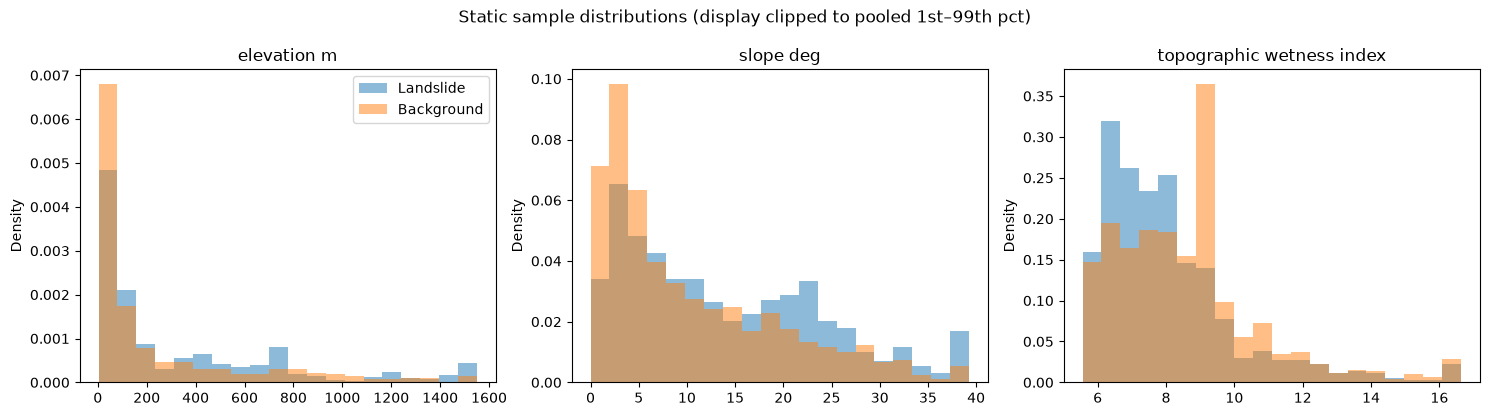

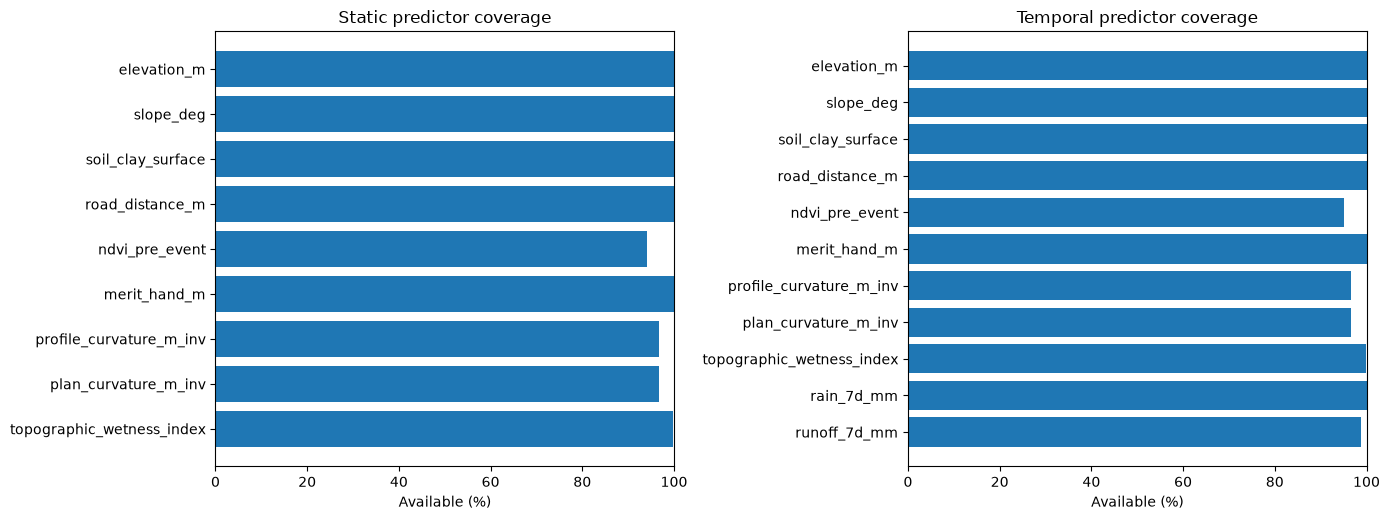

Documentation results saved to: C:\landslide_fyp\outputs\documentation\notebook03
Important: train-only imputation/scaling and the final model feature list remain Notebook 04 responsibilities.


In [1]:
# Section 8 — Safe final sample-level feature integration and screenshot-ready data understanding.
# Standalone: run this cell without executing prior sections 0–7 when model CSVs exist.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT8 = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
              if (p/'data/processed/modelling/static_model_dataset.csv').is_file()), None)
if ROOT8 is None:
    raise FileNotFoundError('Existing Notebook 03 modelling datasets were not found.')
DIR8 = ROOT8/'data/processed/modelling'
F8 = ROOT8/'data/processed/features'
QA8 = ROOT8/'outputs/documentation/notebook03'
QA8.mkdir(parents=True,exist_ok=True)

# Explicit model features only: do not automatically add source flags, future dates or statuses.
ENHANCEMENT_FEATURES8 = ['ndvi_pre_event','ndvi_change_2y',
                         'forest_loss_5y_250m_pct','merit_hand_m',
                         'merit_upstream_area_km2','runoff_7d_mm','runoff_30d_mm']
TERRAIN_FEATURES8 = ['profile_curvature_m_inv','plan_curvature_m_inv',
                     'topographic_wetness_index']
ENHANCEMENT_FILES8 = [F8/'historical_environmental_enhancement_recovery_REVIEW.csv',
                      F8/'historical_environmental_enhancement.csv']
TERRAIN_FILE8 = F8/'terrain_derivatives_v1.csv'

# Choose the reviewed enhancement sidecar when present; otherwise the base sidecar.
enh_path8 = next((p for p in ENHANCEMENT_FILES8 if p.is_file()), None)
sidecars8 = []
for name,path,features in [('historical_enhancement',enh_path8,ENHANCEMENT_FEATURES8),
                           ('terrain_derivatives',TERRAIN_FILE8,TERRAIN_FEATURES8)]:
    if path is None or not path.is_file():
        print('WARNING: Missing',name,'sidecar; expected extra predictors remain absent.')
        continue
    side=pd.read_csv(path,low_memory=False,dtype={'sample_id':str})
    if 'sample_id' not in side:raise ValueError(f'{path.name}: sample_id missing.')
    if side.sample_id.isna().any() or side.sample_id.duplicated().any():
        raise ValueError(f'{path.name}: sample_id must be unique and non-null.')
    present=[c for c in features if c in side.columns]
    if not present:
        print('WARNING: No expected predictor columns found in',path.name)
        continue
    sidecars8.append((name,path,side,present))
    print(name,'source:',path.name,'| predictors:',present,'| rows:',len(side))

integrated8={}; provenance_rows8=[]; matched_checks8=[]
for branch in ('static','temporal'):
    path=DIR8/f'{branch}_model_dataset.csv'
    if not path.is_file(): raise FileNotFoundError(path)
    original=pd.read_csv(path,low_memory=False,dtype={'sample_id':str,'matched_event_id':str})
    required={'sample_id','matched_event_id','target','longitude','latitude'}
    if not required.issubset(original.columns):
        raise ValueError(f'{path.name}: missing {sorted(required-set(original.columns))}')
    if original.sample_id.isna().any() or not original.sample_id.is_unique:
        raise ValueError(f'{path.name}: duplicate/missing sample IDs')
    base_ids=original.sample_id.copy(); df=original.copy()
    original_lons=pd.to_numeric(df.longitude,errors='coerce').to_numpy()
    original_lats=pd.to_numeric(df.latitude,errors='coerce').to_numpy()
    for name,src_path,side,source_fields in sidecars8:
        fields=[c for c in source_fields if branch=='temporal' or not c.startswith('runoff_')]
        if not fields:continue
        common=sorted(set(df.columns)&set(fields))
        newcols=[c for c in fields if c not in df.columns]
        # Reconcile previously included values. Never replace an existing feature silently.
        look=side.set_index('sample_id').reindex(df.sample_id)
        for c in common:
            left=pd.to_numeric(df[c],errors='coerce').to_numpy()
            right=pd.to_numeric(look[c],errors='coerce').to_numpy()
            both=np.isfinite(left)&np.isfinite(right)
            if both.any() and not np.allclose(left[both],right[both],rtol=1e-5,atol=1e-6):
                raise ValueError(f'{branch}/{c}: conflicting existing and sidecar values; manual source review needed.')
            # No fill: original values remain authoritative.
        # Coordinate alignment must use numeric equality at the same actual sample IDs.
        if {'longitude','latitude'}.issubset(side.columns):
            slo=pd.to_numeric(look['longitude'],errors='coerce').to_numpy()
            sla=pd.to_numeric(look['latitude'],errors='coerce').to_numpy()
            have=np.isfinite(slo)&np.isfinite(sla)
            if have.any() and not (np.allclose(slo[have],original_lons[have],rtol=0,atol=1e-6)
                                   and np.allclose(sla[have],original_lats[have],rtol=0,atol=1e-6)):
                raise ValueError(f'{branch}/{name}: sidecar coordinates disagree with actual sample locations.')
        df=df.merge(side[['sample_id']+newcols],on='sample_id',how='left',validate='one_to_one',sort=False)
        for c in fields:
            if c in df:
                df[c]=pd.to_numeric(df[c],errors='coerce')
                provenance_rows8.append({'branch':branch,'feature':c,'source':name,
                                         'source_file':src_path.name,
                                         'available':int(df[c].notna().sum()),
                                         'missing_pct':round(100*df[c].isna().mean(),2)})
    if not df.sample_id.equals(base_ids) or len(df)!=len(original):
        raise AssertionError(f'{branch}: join changed sample IDs or row order')
    if not df[['target','matched_event_id','longitude','latitude']].equals(original[['target','matched_event_id','longitude','latitude']]):
        raise AssertionError(f'{branch}: join changed labels, groups or coordinates')
    cts=df.groupby(['matched_event_id','target']).size().unstack(fill_value=0)
    if not cts.get(1,pd.Series(dtype=int)).eq(1).all() or not cts.get(0,pd.Series(dtype=int)).eq(2).all():
        raise AssertionError(f'{branch}: incomplete 1:2 matched case/control groups')
    integrated8[branch]=df
    matched_checks8.append({'branch':branch,'observations':len(df),'cases':int(df.target.eq(1).sum()),
                            'backgrounds':int(df.target.eq(0).sum()),
                            'matched_groups':df.matched_event_id.nunique(),
                            'columns':len(df.columns)})
    print(branch.upper(),'complete groups:',df.matched_event_id.nunique(),
          '| rows:',len(df),'| columns:',len(df.columns))

# These versioned files are strictly outputs of integration (not original modelling datasets).
# Existing files are retained if identical; changed results require explicit new versioning.
for branch, df in integrated8.items():
    dest=DIR8/f'{branch}_model_dataset_integrated_v1.csv'
    if dest.exists():
        old=pd.read_csv(dest,low_memory=False,dtype={'sample_id':str,'matched_event_id':str})
        try:
            pd.testing.assert_frame_equal(old,df,check_dtype=False,check_exact=False,rtol=1e-8,atol=1e-8)
            print('Reusing identical integrated table:',dest.name)
        except AssertionError as err:
            raise FileExistsError(f'{dest} exists with different contents; version it explicitly before rerunning.') from err
    else:
        df.to_csv(dest,index=False)
        print('Saved:',dest)

counts8=pd.DataFrame(matched_checks8)
source8=pd.DataFrame(provenance_rows8)
counts8.to_csv(QA8/'01_matched_observation_counts.csv',index=False)
source8.to_csv(QA8/'02_sidecar_feature_provenance_completeness.csv',index=False)
display(counts8)
if not source8.empty:display(source8.round(2))

# All numeric environmental model columns by variable name; class-wise summary.
ID8={'target','longitude','latitude','sample_id','matched_event_id','event_candidate_id',
     'parent_block_id','reference_date','event_date','source','control_rank'}
EXCLUDE8={'source_year','window_start','window_end','status','reason','eligible','candidate',
          'latitude_','longitude_','_count','_qa','source_', 'evidence', 'flag'}
metrics8=[]
for branch,df in integrated8.items():
    for c in df.select_dtypes(include='number').columns:
        if c in ID8 or any(s in c.lower() for s in EXCLUDE8):continue
        for label in (0,1):
            vals=pd.to_numeric(df.loc[df.target==label,c],errors='coerce')
            if not vals.notna().any():continue
            metrics8.append({'branch':branch,'feature':c,'target':label,'count':len(vals),
                             'missing_pct':round(100*vals.isna().mean(),2),
                             'median':vals.median(),'p25':vals.quantile(.25),
                             'p75':vals.quantile(.75),'p01':vals.quantile(.01),
                             'p99':vals.quantile(.99)})
summary8=pd.DataFrame(metrics8)
summary8.to_csv(QA8/'03_case_background_feature_descriptives.csv',index=False)

# Screenshot 1 — class-balanced case vs background distributions
fig,axs=plt.subplots(1,3,figsize=(15,4.2))
for ax,c in zip(axs,['elevation_m','slope_deg','topographic_wetness_index']):
    d=integrated8['static'];
    if c not in d.columns:
        ax.text(.5,.5,'Feature not available',ha='center',va='center',transform=ax.transAxes)
    else:
        x=pd.to_numeric(d.loc[d.target==1,c],errors='coerce').dropna()
        y=pd.to_numeric(d.loc[d.target==0,c],errors='coerce').dropna()
        if len(x) and len(y):
            lo,hi=np.nanpercentile(np.r_[x.to_numpy(),y.to_numpy()],[1,99])
            ax.hist(x.clip(lo,hi),bins=20,density=True,alpha=.5,label='Landslide')
            ax.hist(y.clip(lo,hi),bins=20,density=True,alpha=.5,label='Background')
    ax.set_title(c.replace('_',' '));ax.set_ylabel('Density')
axs[0].legend();fig.suptitle('Static sample distributions (display clipped to pooled 1st–99th pct)')
fig.tight_layout()
fig.savefig(QA8/'04_static_case_background_distributions.png',dpi=170,bbox_inches='tight')
plt.show()

# Screenshot 2 — feature coverage by branch; keep separate from the baseline model's imputation.
fig,axs=plt.subplots(1,2,figsize=(14,5.3))
for ax,branch in zip(axs,('static','temporal')):
    df=integrated8[branch]
    picks=[c for c in ['elevation_m','slope_deg','soil_clay_surface','road_distance_m',
                       'ndvi_pre_event','merit_hand_m','profile_curvature_m_inv',
                       'plan_curvature_m_inv','topographic_wetness_index',
                       'rain_7d_mm','runoff_7d_mm'] if c in df]
    vals=[100*pd.to_numeric(df[c],errors='coerce').notna().mean() for c in picks]
    ax.barh(picks,vals);ax.set_xlim(0,100);ax.invert_yaxis()
    ax.set_title(branch.capitalize()+' predictor coverage');ax.set_xlabel('Available (%)')
fig.tight_layout()
fig.savefig(QA8/'05_integrated_feature_completeness.png',dpi=170,bbox_inches='tight')
plt.show()
print('Documentation results saved to:',QA8)
print('Important: train-only imputation/scaling and the final model feature list remain Notebook 04 responsibilities.')